<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%209/MRayhanZamzami_JS09_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 2 - Klasifikasi Naive Bayes dengan Data Dummy

Perbandingan model MultinomialNB vs GaussianNB pada data sintetis make_classification.

## Langkah 1 - Buat Dataset Dummy

In [1]:
import numpy as np
from sklearn.datasets import make_classification

# Buat data dummy
X, y = make_classification(
    n_samples=30, n_features=2, n_classes=2, 
    n_informative=2, n_redundant=0, n_repeated=0, 
    shuffle=False, random_state=42
)

# Konversi nilai ke bilangan bulat positif diskrit
X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print('Fitur X:\n', X[:5])
print('Label y:\n', y[:5])

Fitur X:
 [[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]]
Label y:
 [0 0 0 0 0]


## Langkah 2 - Membuat DataFrame dan Pelabelan

In [2]:
import pandas as pd

y_new = y.reshape(len(y), 1)
data = np.concatenate((X, y_new), axis=1)
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']
df = pd.DataFrame(data, columns=nama_kolom)

# Label kategori
labels = {1: 'Kelas A', 0: 'Kelas B'}
df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,Fitur 1,Fitur 2,Label
0,112,139,Kelas B
1,179,210,Kelas B
2,83,71,Kelas B
3,182,265,Kelas B
4,105,78,Kelas B


## Langkah 3 - Visualisasi Sebaran Data

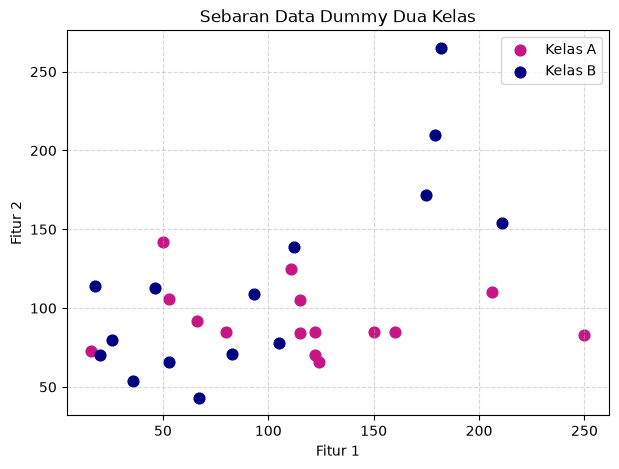

In [3]:
import matplotlib.pyplot as plt

colors = {'class_a': 'MediumVioletRed', 'class_b': 'Navy'}
class_a = df_label[df_label['Label'] == 'Kelas A']
class_b = df_label[df_label['Label'] == 'Kelas B']

plt.figure(figsize=(7, 5))
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'], label='Kelas A', s=60)
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'], label='Kelas B', s=60)
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Sebaran Data Dummy Dua Kelas')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Langkah 4 - Model Multinomial Naive Bayes

In [4]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Split data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=30
)

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

acc_train_mnb = accuracy_score(y_train, mnb.predict(X_train))
acc_test_mnb = accuracy_score(y_test, mnb.predict(X_test))

print(f'Hasil akurasi data train (Multinomial): {acc_train_mnb:.4f}')
print(f'Hasil akurasi data test  (Multinomial): {acc_test_mnb:.4f}')

Hasil akurasi data train (Multinomial): 0.8095
Hasil akurasi data test  (Multinomial): 0.3333


## Langkah 5 - Model Gaussian Naive Bayes

In [5]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

acc_train_gnb = accuracy_score(y_train, gnb.predict(X_train))
acc_test_gnb = accuracy_score(y_test, gnb.predict(X_test))

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb:.4f}')
print(f'Hasil akurasi data test  (Gaussian): {acc_test_gnb:.4f}')

Hasil akurasi data train (Gaussian): 0.8571
Hasil akurasi data test  (Gaussian): 0.4444
